Week_42 
Group 4_3
Name: Djordje Pesut
 , Rishanth Jeevahen


 ***Task 1: Temperature data request***

In [1]:

import requests
import os
from dotenv import load_dotenv
import pandas as pd

load_dotenv()
CLIENT_ID = os.environ["FROST_CLIENT_ID"]


endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}


r = requests.get(endpoint, parameters, auth=(CLIENT_ID, ''))
json_data = r.json()

if r.status_code == 200:
    data = json_data['data']


    rows = []
    for obs in data:
        time = obs['referenceTime']
        for val in obs['observations']:
            rows.append({'referenceTime': time, 'temperature': val['value']})

    df = pd.DataFrame(rows)
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

    print("Data ble hentet ut uten feil!")
    print(df.head())
else:
    print(f"Feil oppsto: {r.status_code}")
    print(json_data['error']['reason'])

Data ble hentet ut uten feil!
              referenceTime  temperature
0 2025-01-01 00:00:00+00:00         -5.2
1 2025-01-01 00:00:00+00:00         -2.8
2 2025-01-02 00:00:00+00:00        -11.5
3 2025-01-02 00:00:00+00:00         -7.2
4 2025-01-03 00:00:00+00:00         -8.9


*PLOT FOR TASK 1*

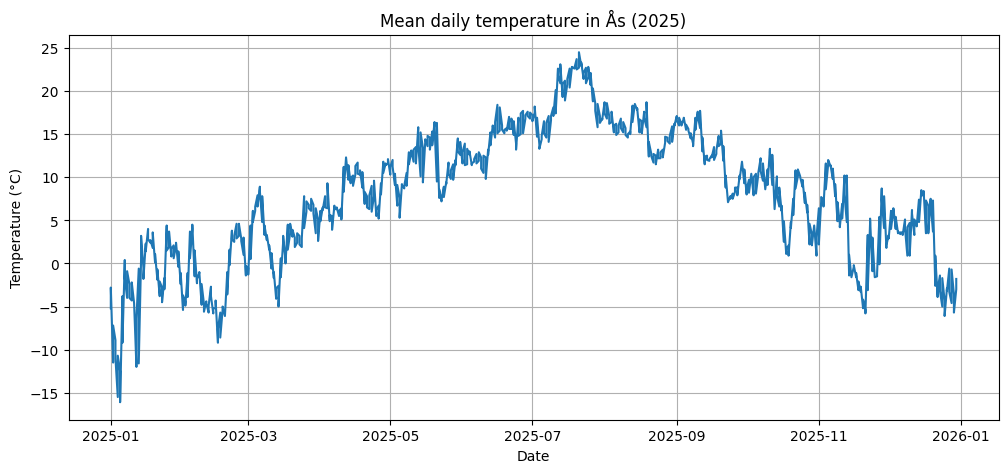

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df['referenceTime'], df['temperature'], color='tab:blue')
plt.title('Mean daily temperature in Ås (2025)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

In [3]:
stats = df['temperature'].agg(['mean', 'median', 'min', 'max'])
print("Summary table for air temperature in Ås 2025:")
print(stats)

Summary table for air temperature in Ås 2025:
mean       7.903571
median     8.350000
min      -16.100000
max       24.500000
Name: temperature, dtype: float64


***TASK 2 - Precipitation***

In [16]:

parameters_2 = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, params=parameters_2, auth=(CLIENT_ID, ''))
r.raise_for_status()
data = r.json()['data']

rows_pt6h = []
for obs in data:
    for val in obs['observations']:
        if val['timeOffset'] == 'PT6H':
            rows_pt6h.append({
                'referenceTime': obs['referenceTime'],
                'precipitation': val['value'],
            })

df_precip_pt6h = pd.DataFrame(rows_pt6h, columns=['referenceTime', 'precipitation'])
df_precip_pt6h['referenceTime'] = pd.to_datetime(df_precip_pt6h['referenceTime'])

sum_precip_pt6h = df_precip_pt6h['precipitation'].sum()
print(f"summen for PT6H: {sum_precip_pt6h} mm")


summen for PT6H: 950.1999999999999 mm


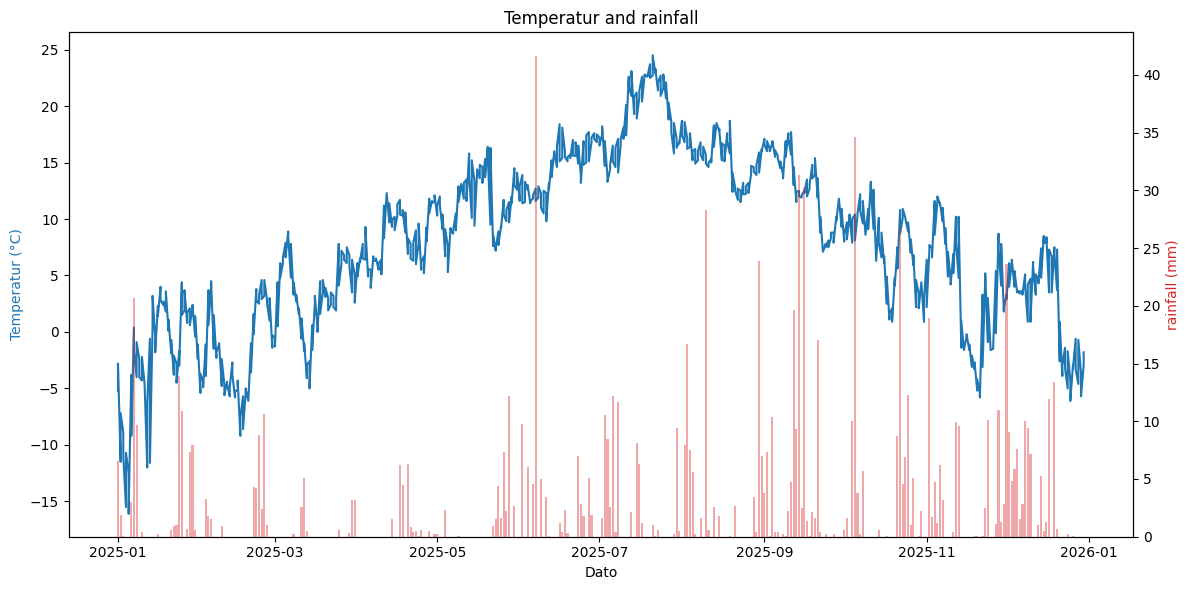

In [15]:
import matplotlib.pyplot as plt
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(df["referenceTime"], df["temperature"], color="tab:blue")
ax1.set_xlabel("Dato")
ax1.set_ylabel("Temperatur (°C)", color="tab:blue")
ax2 = ax1.twinx()
ax2.bar(
df_precip_pt6h['referenceTime'],
df_precip_pt6h['precipitation'],
color='tab:red',
alpha=0.4
)
ax2.set_ylabel('rainfall (mm)', color='tab:red')
ax1.set_title('Temperatur and rainfall')
fig.tight_layout()
plt.show()

Task 3

In [20]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

def get_daily(element, start, end):
    parameters = {
        "sources": "SN17850",
        "elements": element,
        "referencetime": start + "/" + end
    }

    r = requests.get(endpoint, parameters, auth=(CLIENT_ID, ""))
    data = r.json()["data"]

    rows = []
    for item in data:
        for obs in item["observations"]:
            rows.append({
                "time": item["referenceTime"],
                "value": obs["value"]
            })

    df = pd.DataFrame(rows)
    df["time"] = pd.to_datetime(df["time"]).dt.tz_localize(None)
    df = df.drop_duplicates("time")
    return df.sort_values("time")


def summary_table(data):
    result = pd.DataFrame({
        name: {
            "Mean": values.mean(),
            "Median": values.median(),
            "Min": values.min(),
            "Max": values.max()
        }
        for name, values in data.items()
    })
    return result.round(1)

In [24]:
temp_old = get_daily(
    "mean(air_temperature P1D)",
    "1925-01-01",
    "1925-12-31"
)

print(len(temp_old), "days of data in 1925")

364 days of data in 1925


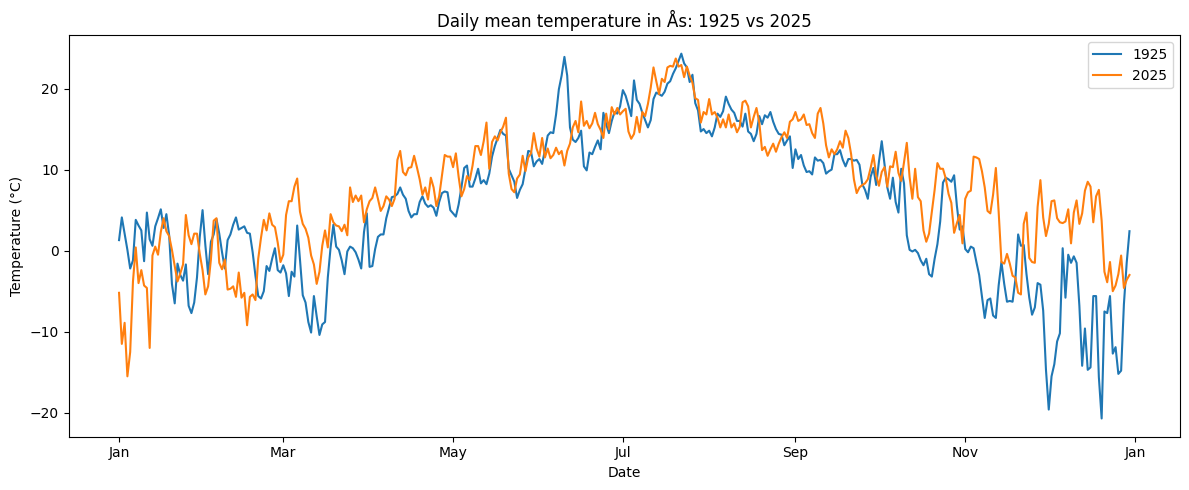

In [25]:
old_aligned = temp_old.copy()
old_aligned["time"] = old_aligned["time"].apply(
    lambda d: d.replace(year=2025)
)

plt.figure(figsize=(12, 5))

plt.plot(old_aligned["time"], old_aligned["value"], label="1925")
plt.plot(temp["time"], temp["value"], label="2025")

plt.title("Daily mean temperature in Ås: 1925 vs 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout()
plt.show()

In [26]:
print(summary_table({
    "1925": temp_old["value"],
    "2025": temp["value"]
}))

        1925  2025
Mean     5.3   7.9
Median   5.3   8.4
Min    -20.7 -15.5
Max     24.3  23.7


Task 4

In [28]:
import yaml as yml

heatwave_params = {
    'sources': 'SN17850',
    'elements': 'max(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}


def heatwaves(heatwave_params: dict) -> pd.DataFrame:

    """Creates a dataframe with every heatwave for the given year and creates a summary yml file"""

    heatwave_r = requests.get(endpoint, heatwave_params, auth=(CLIENT_ID, ''))
    heatwave_r.raise_for_status()
    data = heatwave_r.json()["data"]

    heatwave_rows = []

    # if heatwave_r.status_code == 200:
    # data = json_data['data']

    for obs in data:
        for val in obs['observations']:
            if val['elementId'] == 'max(air_temperature P1D)' and val['value'] >= 27.0:
                heatwave_rows.append({

                    'referenceTime': obs['referenceTime'],
                    'heatwave': val['value']
            })

    df_heatwave = pd.DataFrame(heatwave_rows, columns=["referenceTime", "heatwave"])

    records = df_heatwave.to_dict(orient="records")

    with open("heatwaves.yml", "w", encoding="utf-8") as file:
        yml.safe_dump(
        records,
        file,
        allow_unicode=True,
        sort_keys=False,
    )

    return df_heatwave, records


print(heatwaves(heatwave_params))

(               referenceTime  heatwave
0   2025-07-11T00:00:00.000Z      28.0
1   2025-07-11T00:00:00.000Z      28.0
2   2025-07-12T00:00:00.000Z      28.1
3   2025-07-12T00:00:00.000Z      28.1
4   2025-07-16T00:00:00.000Z      28.3
5   2025-07-16T00:00:00.000Z      28.3
6   2025-07-17T00:00:00.000Z      29.5
7   2025-07-17T00:00:00.000Z      29.5
8   2025-07-18T00:00:00.000Z      30.1
9   2025-07-18T00:00:00.000Z      30.1
10  2025-07-19T00:00:00.000Z      29.9
11  2025-07-19T00:00:00.000Z      29.9
12  2025-07-20T00:00:00.000Z      30.8
13  2025-07-20T00:00:00.000Z      30.8
14  2025-07-21T00:00:00.000Z      28.6
15  2025-07-22T00:00:00.000Z      28.4
16  2025-07-22T00:00:00.000Z      28.4
17  2025-07-24T00:00:00.000Z      29.4
18  2025-07-24T00:00:00.000Z      29.4
19  2025-07-25T00:00:00.000Z      27.6
20  2025-07-25T00:00:00.000Z      27.6, [{'referenceTime': '2025-07-11T00:00:00.000Z', 'heatwave': 28.0}, {'referenceTime': '2025-07-11T00:00:00.000Z', 'heatwave': 28.0}, {'referen

In [12]:
def moving_average(values, window=7):
    return pd.Series(values).rolling(window=window, center=True).mean()

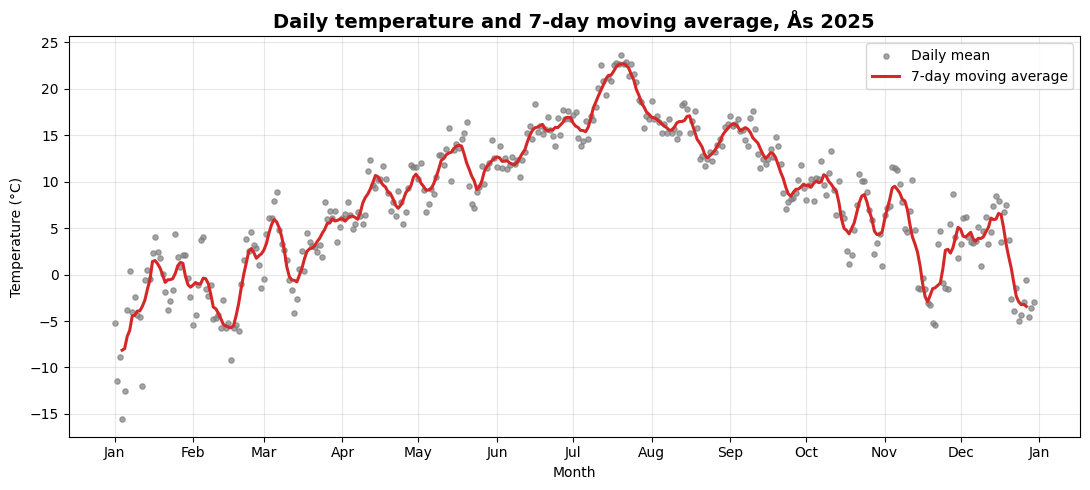

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_2025 = temp.rename(columns={"time": "date", "value": "temperature"})[
        ["date", "temperature"]
].copy()
df_2025["ma7"] = moving_average(df_2025["temperature"], window=7)

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(df_2025["date"], df_2025["temperature"], s=14, color="tab:gray",
           alpha=0.7, label="Daily mean")
ax.plot(df_2025["date"], df_2025["ma7"], color="tab:red", lw=2.2,
        label="7-day moving average")
ax.set_title("Daily temperature and 7-day moving average, Ås 2025",
             fontsize=14, weight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()